<a href="https://colab.research.google.com/github/LeticiaMatsune/cn/blob/main/ATV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Estabilidade e overflow

Maior float32: 3.4028235e+38
Maior float64: 1.7976931348623157e+308
dt=0.001, float32: 2000 passos sem overflow.
dt=0.002, float32: falha no passo 121, t=0.2420 s - overflow encountered in subtract
dt=0.001, float64: 2000 passos sem overflow.
dt=0.002, float64: falha no passo 917, t=1.8340 s - overflow encountered in add


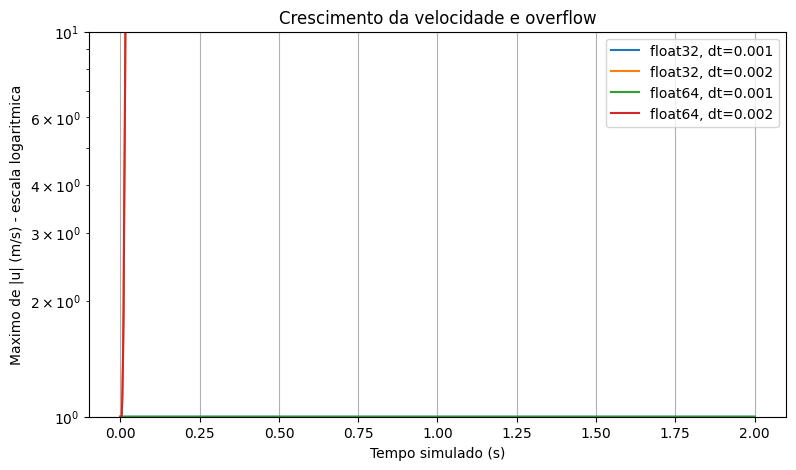

In [8]:
import numpy as np
import matplotlib.pyplot as plt


def simular(dt, tipo=np.float32, passos=2000, pontos=21):
    """Simula difusao de velocidade e detecta falhas."""

    H = 0.01
    nu = 1e-4

    y = np.linspace(0, H, pontos)
    dy = H / (pontos - 1)

    # Coeficientes no tipo numerico escolhido.
    r = tipo(nu * dt / dy**2)
    dois = tipo(2)

    # Fluido parado e placa em y=0 em movimento.
    u = np.zeros(pontos, dtype=tipo)
    u[0] = tipo(1)

    tempos = [0.0]
    maximos = [float(np.max(np.abs(u)))]
    falha = None

    # Transforma avisos numericos em excecoes.
    with np.errstate(over="raise", invalid="raise"):
        for passo in range(1, passos + 1):
            try:
                novo = u.copy()

                # Atualiza o interior e preserva as paredes.
                novo[1:-1] = (
                    u[1:-1]
                    + r * (
                        u[2:] - dois * u[1:-1] + u[:-2]
                    )
                )

            except FloatingPointError as erro:
                falha = passo
                print(
                    f"dt={dt}, {tipo.__name__}: "
                    f"falha no passo {passo}, "
                    f"t={passo * dt:.4f} s - {erro}"
                )
                break

            u = novo
            tempos.append(passo * dt)
            maximos.append(float(np.max(np.abs(u))))

    if falha is None:
        print(
            f"dt={dt}, {tipo.__name__}: "
            f"{passos} passos sem overflow."
        )

    return {
        "y": y,
        "u": u,
        "tempos": tempos,
        "maximos": maximos,
        "r": float(r),
        "falha": falha,
    }


print("Maior float32:", np.finfo(np.float32).max)
print("Maior float64:", np.finfo(np.float64).max)

resultados = {}

for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        nome = f"{tipo.__name__}, dt={dt}"
        resultados[nome] = simular(dt, tipo)

plt.figure(figsize=(9, 5))

for nome, resultado in resultados.items():
    plt.semilogy(
        resultado["tempos"],
        resultado["maximos"],
        label=nome
    )

plt.xlabel("Tempo simulado (s)")
plt.ylabel("Maximo de |u| (m/s) - escala logaritmica")
plt.title("Crescimento da velocidade e overflow")
plt.grid(True)
plt.legend()
plt.show()

# 1. Verificação da estabilidade


Δy = 0,01/20 = 0,0005 m

Δtₘₐₓ = Δy²/(2ν) = (0,0005)²/[2(10⁻⁴)] = 0,00125 s

### Caso A
Δt = 0,001 s:

r = 10⁻⁴·0,001/(0,0005)² = 0,4

Como 0,4 ≤ 0,5, o caso A é estável

### Caso B
Δt = 0,002 s:

r = 10⁻⁴·0,002/(0,0005)² = 0,8

Como 0,8 > 0,5, o caso B é instável

A condição r ≤ 1/2 é a condição de estabilidade do esquema utilizado.


In [2]:
H = 0.01
nu = 1e-4
pontos = 21
dy = H / (pontos - 1)
dtmax = dy**2 / (2 * nu)

casos = pd.DataFrame({
    "Caso": ["A", "B"],
    "Delta t (s)": [0.001, 0.002],
    "r": [nu*0.001/dy**2, nu*0.002/dy**2]
})
casos["Classificação"] = np.where(casos["r"] <= 0.5, "Estável", "Instável")

print(f"Delta y = {dy:.7f} m")
print(f"Delta t_max = {dtmax:.7f} s")
display(casos)


Delta y = 0.0005000 m
Delta t_max = 0.0012500 s


,Caso,Delta t (s),r,Classificação
0,A,0.001,0.4,Estável
1,B,0.002,0.8,Instável


# 2. Detecção de overflow

Serão executados os quatro testes pedidos: Δt = 0,001 e 0,002 s com `float32` e `float64`. fileciteturn0file0L237-L245


In [3]:
resultados = {}

for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        nome = f"{tipo.__name__}, dt={dt}"
        resultados[nome] = simular(dt, tipo=tipo, passos=2000, pontos=21)

linhas = []
for resultado in resultados.values():
    linhas.append({
        "Tipo numérico": resultado["tipo"],
        "Delta t (s)": resultado["dt"],
        "r": resultado["r"],
        "Overflow": "Sim" if resultado["falha"] is not None else "Não",
        "Iteração da falha": resultado["falha"] if resultado["falha"] is not None else "—"
    })

tabela_testes = pd.DataFrame(linhas)
display(tabela_testes)


,Tipo numérico,Delta t (s),r,Overflow,Iteração da falha
0,float32,0.001,0.4,Não,—
1,float32,0.002,0.8,Sim,121
2,float64,0.001,0.4,Não,—
3,float64,0.002,0.8,Sim,917


# 3. Interpretação física

A velocidade física deve permanecer no intervalo 0 ≤ u ≤ U = 1 m/s. Portanto, velocidades muito maiores que 1 m/s já indicam uma solução incorreta, mesmo que ainda não tenha ocorrido overflow.

No caso estável, a viscosidade transmite gradualmente o movimento da placa móvel para o fluido. No caso instável, r > 1/2 faz com que o coeficiente central (1−2r) seja negativo. Isso permite oscilações que crescem, produzindo velocidades cada vez maiores e não físicas, até ocorrer overflow.


# 4. Capacidade de representação

Trocar `float32` por `float64` não elimina a instabilidade. A causa continua sendo r = 0,8 > 0,5.

A diferença é que `float64` possui uma faixa de representação muito maior. Assim, ele consegue armazenar os valores crescentes por mais tempo e o overflow ocorre depois.

Neste caso:
- `float32`: falha no passo 121;
- `float64`: falha no passo 917.

Logo, aumentar a precisão pode adiar o overflow, mas não corrige a causa numérica.


# 5. Refinamento da malha

Com 41 pontos:

Δy = 0,01/(41−1) = 0,00025 m

Novo limite:

Δtₘₐₓ = (0,00025)²/[2(10⁻⁴)] = 0,0003125 s

Se mantivermos Δt = 0,001 s:

r = 10⁻⁴·0,001/(0,00025)² = 1,6

Portanto, o cálculo fica instável

Escolhendo Δt = 0,00025 s:

r = 0,4

e a simulação volta a ser estável.

Isso mostra que, ao refinar a malha, também é necessário reduzir o passo de tempo para respeitar a condição de estabilidade.


In [5]:
pontos_ref = 41
dy_ref = H / (pontos_ref - 1)
dtmax_ref = dy_ref**2 / (2 * nu)

print(f"41 pontos: Delta y = {dy_ref:.7f} m")
print(f"Novo Delta t_max = {dtmax_ref:.7f} s")

refinamento_instavel = simular(0.001, np.float64, passos=2000, pontos=41)
refinamento_estavel = simular(0.00025, np.float64, passos=2000, pontos=41)

print("\n41 pontos e dt = 0,001 s:")
print(f"r = {refinamento_instavel['r']:.2f}")
print(f"falha = {refinamento_instavel['falha']}")

print("\n41 pontos e dt = 0,00025 s:")
print(f"r = {refinamento_estavel['r']:.2f}")
print(f"falha = {refinamento_estavel['falha']}")


41 pontos: Delta y = 0.0002500 m
Novo Delta t_max = 0.0003125 s

41 pontos e dt = 0,001 s:
r = 1.60
falha = 426

41 pontos e dt = 0,00025 s:
r = 0.40
falha = None


# 6. Verificação do perfil de velocidade

A solução estacionária fornecida na atividade é:

uₑₛₜ(y) = U(1 − y/H)

Ela representa o regime estacionário, não todo o transiente. Por isso, usamos uma simulação suficientemente longa antes de comparar os perfis.


In [6]:
dt_final = 0.00025
passos_final = 10000

final = simular(dt_final, np.float64, passos=passos_final, pontos=41)

y = final["y"]
u_numerica = final["u"]
u_est = 1.0 * (1 - y / H)

E_inf = np.max(np.abs(u_numerica - u_est))

print(f"Delta t = {dt_final} s")
print(f"Passos = {passos_final}")
print(f"Tempo total = {passos_final * dt_final:.2f} s")
print(f"r = {final['r']:.2f}")
print(f"Falha = {final['falha']}")
print(f"Erro máximo E_inf = {E_inf:.6e} m/s")


Delta t = 0.00025 s
Passos = 10000
Tempo total = 2.50 s
r = 0.40
Falha = None
Erro máximo E_inf = 1.202688e-11 m/s


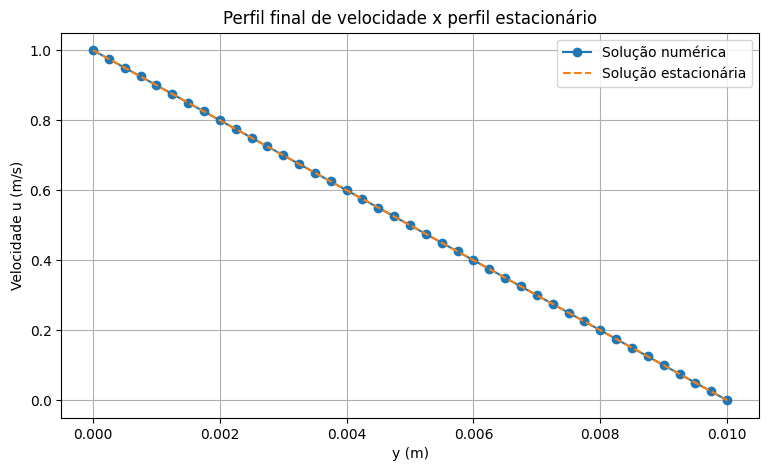

In [7]:
plt.figure(figsize=(9,5))
plt.plot(y, u_numerica, "o-", label="Solução numérica")
plt.plot(y, u_est, "--", label="Solução estacionária")
plt.xlabel("y (m)")
plt.ylabel("Velocidade u (m/s)")
plt.title("Perfil final de velocidade x perfil estacionário")
plt.grid(True)
plt.legend()
plt.show()


### Interpretação

Usando 41 pontos, Δt = 0,00025 s e 10000 passos, o tempo total simulado é 2,5 s. Como r = 0,4, a execução é estável e o perfil numérico fica praticamente sobre o perfil estacionário linear.

O erro máximo obtido é aproximadamente:

E∞ = 1,20×10⁻¹¹ m/s

Portanto, para essa execução, o transiente foi suficientemente reduzido e a solução está muito próxima do regime estacionário.


# 7. Conclusão

O refinamento da malha aumenta a resolução espacial, mas também torna a restrição temporal mais severa, pois:

Δt ≤ Δy²/(2ν)

Com 21 pontos, Δy = 0,0005 m e Δtₘₐₓ = 0,00125 s. O caso A (Δt = 0,001 s) tem r = 0,4 e é estável; o caso B (Δt = 0,002 s) tem r = 0,8 e é instável.

Ao refinar para 41 pontos, Δy passa para 0,00025 m e Δtₘₐₓ cai para 0,0003125 s. Assim, manter Δt = 0,001 s produz r = 1,6 e mantém o cálculo instável. Reduzir o passo para Δt = 0,00025 s produz r = 0,4 e corrige a causa da falha.

Conclusão principal: o overflow é uma consequência da instabilidade numérica. Trocar `float32` por `float64` apenas adia o overflow; a correção efetiva é escolher um passo de tempo que respeite a condição de estabilidade.


## Resumo dos resultados

| Situação | Δy (m) | Δt (s) | r | Resultado |
|---|---:|---:|---:|---|
| 21 pontos — A | 0,0005 | 0,001 | 0,4 | Estável |
| 21 pontos — B | 0,0005 | 0,002 | 0,8 | Instável + overflow |
| 41 pontos — Δt = 0,001 | 0,00025 | 0,001 | 1,6 | Instável + overflow |
| 41 pontos — Δt = 0,00025 | 0,00025 | 0,00025 | 0,4 | Estável |


